Manual

--- Memulai Pencarian Parameter XGBoost Terbaik ---
Parameter Terbaik Ditemukan: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 50}

--- LAPORAN EVALUASI PERFORMA MODEL MANUAL ---
Rata-rata Pendapatan Asli (Test Set) : 17,821,761.98
-----------------------------------------------
1. MAE (Kesalahan Rata-rata Absolut) : 3,506,931.33
2. RMSE (Penalti Kesalahan Besar)    : 4,564,941.55
3. MAPE (Persentase Kesalahan)       : 25.66 %
-----------------------------------------------
MAE Baseline (Tebakan Polos)         : 5,721,012.32

--- KESIMPULAN ---
STATUS: BAGUS. Model Hybrid mengalahkan tebakan sederhana.
File gambar 'prediksi.png' berhasil disimpan!


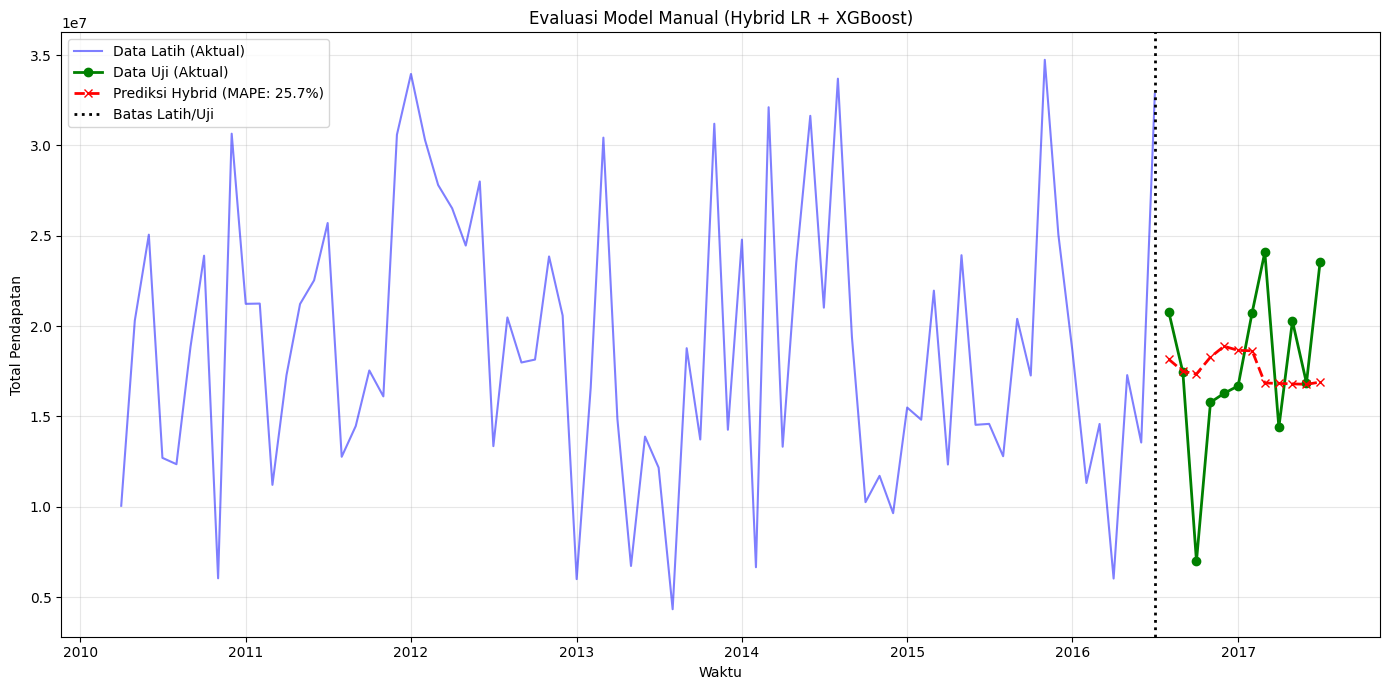

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import warnings
warnings.filterwarnings('ignore')

# ---------------------------------------------
# TAHAP 1: PEMUATAN DATA & AGREGASI
# ---------------------------------------------
file_path = "Europe Sales Records.csv"
df = pd.read_csv(file_path)

df['Order Date'] = pd.to_datetime(df['Order Date'])
df = df.set_index('Order Date').sort_index()

# Agregasi Total Pendapatan Bulanan Global
df_monthly = df[['Total Revenue']].resample('MS').sum()
df_monthly.fillna(0, inplace=True)

# ---------------------------------------------
# TAHAP 2: FEATURE ENGINEERING
# ---------------------------------------------
df_monthly['Time_Step'] = np.arange(len(df_monthly))
df_monthly['Month'] = df_monthly.index.month
df_monthly['Revenue_Lag1'] = df_monthly['Total Revenue'].shift(1)

# PERBAIKAN 1: Ambil Kuartal langsung dari index, bukan dari kolom
df_monthly['Kuartal'] = df_monthly.index.quarter 
df_monthly['Rolling_Mean_3'] = df_monthly['Total Revenue'].shift(1).rolling(window=3).mean()

df_clean = df_monthly.dropna()

X = df_clean[['Time_Step', 'Month', 'Revenue_Lag1', 'Kuartal', 'Rolling_Mean_3']]
y = df_clean['Total Revenue']

# ---------------------------------------------
# TAHAP 3: TRAIN-TEST SPLIT (12 BULAN TERAKHIR)
# ---------------------------------------------
test_size = 12
X_train, X_test = X.iloc[:-test_size], X.iloc[-test_size:]
y_train, y_test = y.iloc[:-test_size], y.iloc[-test_size:]

# ---------------------------------------------
# TAHAP 4: MACHINE LEARNING (BOOSTED HYBRID DENGAN TUNING)
# ---------------------------------------------
# Model 1: Regresi Linear (Tren)
model_trend = LinearRegression()
model_trend.fit(X_train[['Time_Step']], y_train)

y_trend_train = model_trend.predict(X_train[['Time_Step']])
y_trend_test = model_trend.predict(X_test[['Time_Step']])
y_resid_train = y_train - y_trend_train

# Model 2: XGBoost dengan TimeSeriesSplit & GridSearchCV
tscv = TimeSeriesSplit(n_splits=4)

param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5]
}

xgb_base = XGBRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# PERBAIKAN 2: Mendaftarkan seluruh fitur baru untuk dianalisis oleh XGBoost
fitur_xgboost = ['Month', 'Revenue_Lag1', 'Kuartal', 'Rolling_Mean_3']

print("--- Memulai Pencarian Parameter XGBoost Terbaik ---")
grid_search.fit(X_train[fitur_xgboost], y_resid_train)

model_xgb_best = grid_search.best_estimator_
print(f"Parameter Terbaik Ditemukan: {grid_search.best_params_}")

# PERBAIKAN 3: Prediksi Residual pada Data Uji menggunakan seluruh fitur baru
y_resid_test = model_xgb_best.predict(X_test[fitur_xgboost])

# ---------------------------------------------
# TAHAP 5: EVALUASI AKHIR & KOMPARASI BASELINE
# ---------------------------------------------
y_pred_test = y_trend_test + y_resid_test

# 1. Perhitungan Metrik Hybrid Model
mae = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
mape = mean_absolute_percentage_error(y_test, y_pred_test)

# 2. Perhitungan Naive Baseline
y_pred_naive = X_test['Revenue_Lag1']
mae_naive = mean_absolute_error(y_test, y_pred_naive)

print("\n--- LAPORAN EVALUASI PERFORMA MODEL MANUAL ---")
print(f"Rata-rata Pendapatan Asli (Test Set) : {y_test.mean():,.2f}")
print(f"-----------------------------------------------")
print(f"1. MAE (Kesalahan Rata-rata Absolut) : {mae:,.2f}")
print(f"2. RMSE (Penalti Kesalahan Besar)    : {rmse:,.2f}")
print(f"3. MAPE (Persentase Kesalahan)       : {mape * 100:.2f} %")
print(f"-----------------------------------------------")
print(f"MAE Baseline (Tebakan Polos)         : {mae_naive:,.2f}")

print("\n--- KESIMPULAN ---")
if mae < mae_naive:
    print("STATUS: BAGUS. Model Hybrid mengalahkan tebakan sederhana.")
else:
    print("STATUS: BURUK. Pembelajaran gagal melampaui tebakan nilai bulan lalu.")

# ---------------------------------------------
# TAHAP 6: VISUALISASI HASIL TESTING
# ---------------------------------------------
plt.figure(figsize=(14, 7))
plt.plot(y_train.index, y_train, label='Data Latih (Aktual)', color='blue', alpha=0.5)
plt.plot(y_test.index, y_test, label='Data Uji (Aktual)', color='green', marker='o', linewidth=2)
plt.plot(y_test.index, y_pred_test, label=f'Prediksi Hybrid (MAPE: {mape*100:.1f}%)', color='red', linestyle='--', marker='x', linewidth=2)

plt.axvline(x=y_train.index[-1], color='black', linestyle=':', linewidth=2, label='Batas Latih/Uji')

plt.title('Evaluasi Model Manual (Hybrid LR + XGBoost)')
plt.xlabel('Waktu')
plt.ylabel('Total Pendapatan')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# 1. SIMPAN GAMBAR TERLEBIH DAHULU (Tambahkan .png)
plt.savefig("prediksi.png", dpi=300, bbox_inches='tight')
print("File gambar 'prediksi.png' berhasil disimpan!")

# 2. BARU TAMPILKAN GAMBAR (Jika Anda tidak butuh pop-up gambar di layar, hapus saja plt.show ini)
plt.show() 

# 3. TUTUP KANVAS
plt.close()

In [ ]:
import bot_telegram as bot

bot.telegram("CHAT ID", "prediksi.png", "*Prediksi Sales*")


--- Mengirim Gambar ke Telegram ---
[SUKSES] Gambar berhasil dikirim ke Telegram!


Auto ( versi 2 )

Beginning AutoGluon training... Time limit = 300s
AutoGluon will save models to '/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/final/AutogluonModels/ag-20260514_081606'


--- Memulai Pelatihan AutoGluon (Machine Learning Only) ---


=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25 PST 2025; root:xnu-12377.61.12~1/RELEASE_ARM64_T8122
CPU Count:          8
Pytorch Version:    2.9.1
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       1.47 GB / 8.00 GB (18.4%)
Disk Space Avail:   10.43 GB / 228.27 GB (4.6%)
Setting presets to: fast_training

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': MAE,
 'excluded_model_types': ['Naive',
                          'SeasonalNaive',
                          'ETS',
                          'AutoETS',
                          'Theta',
                          'ARIMA',
                          'AutoARIMA'],
 'freq': 'MS',
 'hyperparameters': 'very_light',
 'known_covariates_names': [


--- LAPORAN EVALUASI PERFORMA MODEL AUTOGLUON ---
Rata-rata Pendapatan Asli (Test Set) : 17,821,761.98
-----------------------------------------------
1. MAE (Kesalahan Rata-rata Absolut) : 3,663,555.05
2. RMSE (Penalti Kesalahan Besar)    : 4,674,001.90
3. MAPE (Persentase Kesalahan)       : 27.04 %
-----------------------------------------------
MAE Baseline (Tebakan Polos)         : 5,721,012.32

--- KESIMPULAN ---
STATUS: BAGUS. Model AutoGluon mengalahkan tebakan sederhana.


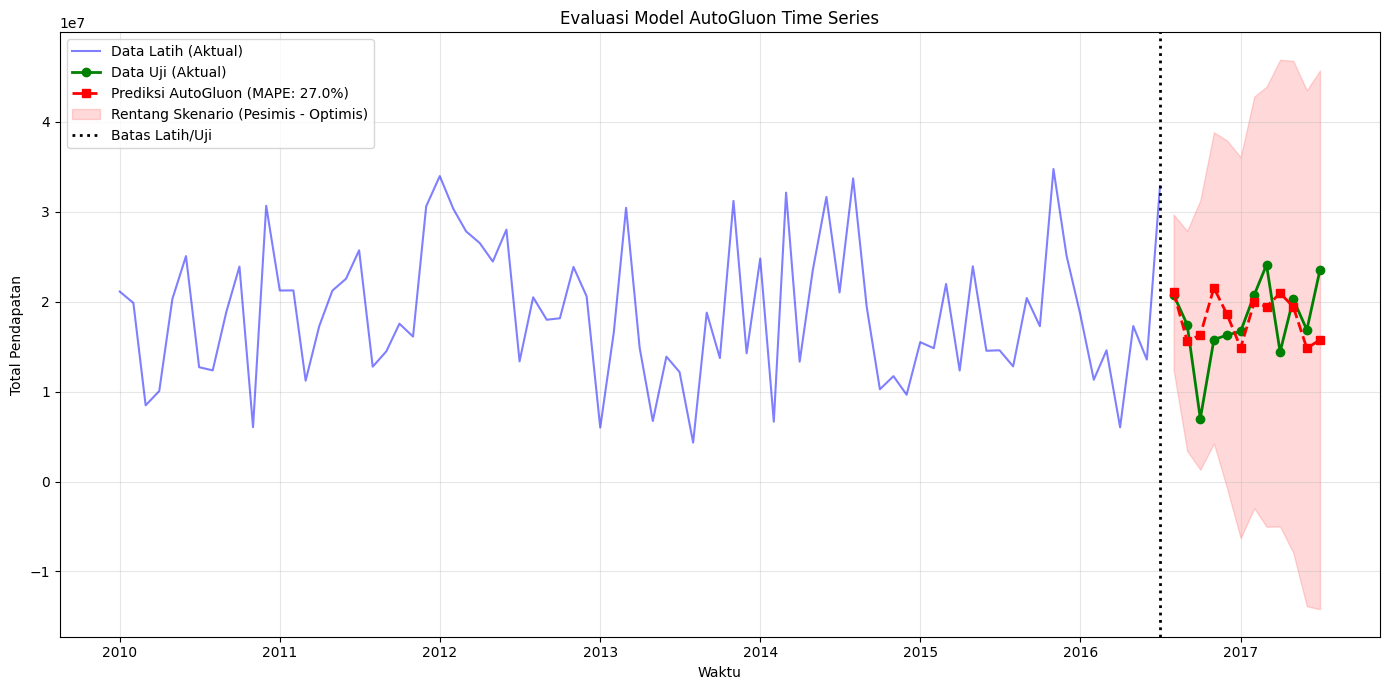

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import warnings
warnings.filterwarnings('ignore')

# ---------------------------------------------------------
# TAHAP 1: PEMUATAN DATA & AGREGASI GLOBAL
# ---------------------------------------------------------
file_path = "Europe Sales Records.csv"
df = pd.read_csv(file_path)

df['Order Date'] = pd.to_datetime(df['Order Date'])
df = df.set_index('Order Date').sort_index()

# Agregasi global 
df_monthly = df[['Total Revenue']].resample('MS').sum().reset_index()
df_monthly['item_id'] = 'Global_Sales'
df_monthly.fillna(0, inplace=True)

# Feature Engineering
df_monthly['Time_Step'] = np.arange(len(df_monthly))
df_monthly['Month'] = df_monthly.index.month
df_monthly['Revenue_Lag1'] = df_monthly['Total Revenue'].shift(1)
df_monthly['Kuartal'] = df_monthly['Order Date'].dt.quarter
df_monthly['Rolling_Mean_3'] = df_monthly['Total Revenue'].shift(1).rolling(window=3).mean()

df_clean = df_monthly.dropna()

# ---------------------------------------------------------
# TAHAP 2: TRAIN-TEST SPLIT (12 BULAN TERAKHIR)
# ---------------------------------------------------------
test_size = 12

df_train = df_monthly.iloc[:-test_size].copy()
df_test = df_monthly.iloc[-test_size:].copy()

df_monthly['Revenue_Lag1'] = df_monthly['Total Revenue'].shift(1)
df_test_lag1 = df_monthly.iloc[-test_size:]['Revenue_Lag1']

# ---------------------------------------------------------
# TAHAP 3: KONVERSI KE AUTOGLUON DATAFRAME
# ---------------------------------------------------------
# Pembelajaran hanya dilakukan pada himpunan Data Latih
train_data = TimeSeriesDataFrame.from_data_frame(
    df_train,
    id_column="item_id",
    timestamp_column="Order Date"
)

# ---------------------------------------------------------
# TAHAP 4: PELATIHAN (TRAINING) DENGAN PEMBATASAN MODEL
# ---------------------------------------------------------
predictor = TimeSeriesPredictor(
    prediction_length=12, 
    target="Total Revenue", 
    known_covariates_names=['Time_Step', 'Month', 'Revenue_Lag1', 'Kuartal', 'Rolling_Mean_3'], # <--- INI KUNCI RAHASIANYA
    eval_metric="MAE",
    freq="MS"
)

print("--- Memulai Pelatihan AutoGluon (Machine Learning Only) ---")
predictor.fit(
    train_data,
    presets="fast_training",    # Tingkatkan preset agar arsitektur Tabular & Deep Learning diaktifkan
    time_limit=300,            # Berikan waktu 5 menit karena model ML butuh waktu lebih lama untuk belajar
    excluded_model_types=[
        'Naive', 
        'SeasonalNaive', 
        'ETS', 
        'AutoETS', 
        'Theta', 
        'ARIMA', 
        'AutoARIMA'
    ] # <--- KUNCI RAHASIA: Memblokir seluruh model statistik klasik (Univariate)
)

# ---------------------------------------------------------
# TAHAP 5: PREDIKSI DAN EVALUASI AKHIR PADA DATA UJI
# ---------------------------------------------------------

# 1. Ekstraksi fitur masa depan dari data uji yang sudah dipotong di Tahap 2
future_covariates = TimeSeriesDataFrame.from_data_frame(
    df_test[['item_id', 'Order Date', 'Time_Step', 'Month', 'Revenue_Lag1', 'Kuartal', 'Rolling_Mean_3']],
    id_column="item_id",
    timestamp_column="Order Date"
)

# 2. Lakukan prediksi dengan menyertakan matriks fitur masa depan tersebut
predictions = predictor.predict(
    train_data,
    known_covariates=future_covariates
)

y_pred_auto = predictions['mean'].values
y_test_aktual = df_test['Total Revenue'].values

# 1. Perhitungan Metrik Model AutoGluon
mae = mean_absolute_error(y_test_aktual, y_pred_auto)
rmse = np.sqrt(mean_squared_error(y_test_aktual, y_pred_auto))
mape = mean_absolute_percentage_error(y_test_aktual, y_pred_auto)

# 2. Perhitungan Naive Baseline
y_pred_naive = df_test_lag1.values
mae_naive = mean_absolute_error(y_test_aktual, y_pred_naive)

print("\n--- LAPORAN EVALUASI PERFORMA MODEL AUTOGLUON ---")
print(f"Rata-rata Pendapatan Asli (Test Set) : {y_test_aktual.mean():,.2f}")
print(f"-----------------------------------------------")
print(f"1. MAE (Kesalahan Rata-rata Absolut) : {mae:,.2f}")
print(f"2. RMSE (Penalti Kesalahan Besar)    : {rmse:,.2f}")
print(f"3. MAPE (Persentase Kesalahan)       : {mape * 100:.2f} %")
print(f"-----------------------------------------------")
print(f"MAE Baseline (Tebakan Polos)         : {mae_naive:,.2f}")

print("\n--- KESIMPULAN ---")
if mae < mae_naive:
    print("STATUS: BAGUS. Model AutoGluon mengalahkan tebakan sederhana.")
else:
    print("STATUS: BURUK. Pembelajaran gagal melampaui tebakan nilai bulan lalu.")

# ---------------------------------------------------------
# TAHAP 6: VISUALISASI HASIL TESTING
# ---------------------------------------------------------
train_dates = df_train['Order Date']
test_dates = df_test['Order Date']

plt.figure(figsize=(14, 7))

plt.plot(train_dates, df_train['Total Revenue'], label='Data Latih (Aktual)', color='blue', alpha=0.5)
plt.plot(test_dates, df_test['Total Revenue'], label='Data Uji (Aktual)', color='green', marker='o', linewidth=2)
plt.plot(test_dates, y_pred_auto, label=f'Prediksi AutoGluon (MAPE: {mape*100:.1f}%)', color='red', linestyle='--', marker='s', linewidth=2)

plt.fill_between(test_dates, 
                 predictions['0.1'].values, 
                 predictions['0.9'].values, 
                 color='red', alpha=0.15, label='Rentang Skenario (Pesimis - Optimis)')

plt.axvline(x=train_dates.iloc[-1], color='black', linestyle=':', linewidth=2, label='Batas Latih/Uji')

plt.title('Evaluasi Model AutoGluon Time Series')
plt.xlabel('Waktu')
plt.ylabel('Total Pendapatan')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()